# Predicting stated roommate desirability from bedtime and cleanliness
InterNest · Lab Assignment №6

**Question.** How accurately can two candidate lifestyle attributes predict 1–7 hypothetical roommate ratings from held-out US student respondents?

A rating is one person's stated willingness to live with a described profile. The unit of independent sampling is the respondent. This experiment informs how InterNest might evaluate future feedback models.

In [1]:
from pathlib import Path
from hashlib import sha256

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

SEED = 42
FEATURES = ['attr_bedtime', 'attr_cleanliness']
KEY = ['id', 'task', 'profile']
TARGET = 'rating'
source = Path('../data/shafranek_2021_roommate_choice.csv')
if not source.is_file():
    source = Path('ml/data/shafranek_2021_roommate_choice.csv')
digest = sha256(source.read_bytes()).hexdigest()
assert digest == '79ea9d09082bbb6c1b247ea8e535ce03e376da922ad79f36ab11651ba981bb27'
raw = pd.read_csv(source)
print(f'IRW v5.0 | SHA-256 {digest} | shape {raw.shape} | respondents {raw.id.nunique()}')

IRW v5.0 | SHA-256 79ea9d09082bbb6c1b247ea8e535ce03e376da922ad79f36ab11651ba981bb27 | shape (4036, 57) | respondents 203


## Data and quality checks
The [original paper](https://faculty.wcas.northwestern.edu/jnd260/pub/Shafranek2021_PoliticalConsiderations.pdf) reports a randomized conjoint survey. Each task shows two hypothetical profiles, with separate ratings and a forced choice. See [data acquisition](../data/README.md) for the export provenance.

Audit all columns by storage type and missingness counts while keeping row-level sensitive values private. Audit exact full-row duplicates and duplicate observation keys separately. Repeated combinations of bedtime and cleanliness are expected in a conjoint and represent separate judgments.

In [2]:
audit = pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum()})
with pd.option_context('display.max_rows', None):
    display(audit)
print('Exact full-row duplicates:', raw.duplicated().sum())
print('Duplicate respondent/task/profile keys:', raw.duplicated(KEY).sum())
assert not raw.duplicated(KEY).any() and not raw[KEY].isna().any().any()
assert raw[TARGET].dropna().isin(range(1, 8)).all()
assert raw['choice'].dropna().isin([0, 1]).all()
print('Choice and rating missingness cross-tab:')
display(pd.crosstab(raw.rating.isna(), raw.choice.isna(), rownames=['Rating missing'],
                    colnames=['Choice missing']))

data = raw[KEY + FEATURES + [TARGET, 'choice']].dropna(subset=[TARGET]).copy()
print(f'Usable ratings: {len(data)} / {len(raw)}; respondents: {data.id.nunique()}')
print('Later rows use only the explicit predictor allowlist:', FEATURES)

,dtype,missing
id,int64,0
task,int64,0
profile,int64,0
choice,float64,82
rating,float64,720
attr_race,object,0
attr_sexual_orientation,object,0
attr_religion,object,0
attr_party,object,0
attr_political_interest,object,0


Choice missing,False,True
Rating missing,,
False,3240,76
True,714,6


Exact full-row duplicates: 0
Duplicate respondent/task/profile keys: 0
Choice and rating missingness cross-tab:
Usable ratings: 3316 / 4036; respondents: 199
Later rows use only the explicit predictor allowlist: ['attr_bedtime', 'attr_cleanliness']


## Respondent-level split and EDA
Assign approximately 70/15/15% of rated respondents with a fixed seed before fitting preprocessing or exploring relationships. Keep validation for model selection and test for final reporting. A whole-file structural audit above records dataset integrity and outcome availability. Relationships below use training only.

In [3]:
outer = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_idx, holdout_idx = next(outer.split(data, groups=data.id))
train, holdout = data.iloc[train_idx], data.iloc[holdout_idx]
inner = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
val_idx, test_idx = next(inner.split(holdout, groups=holdout.id))
validation, test = holdout.iloc[val_idx], holdout.iloc[test_idx]
splits = {'Train': train, 'Validation': validation, 'Test': test}
groups = [set(part.id) for part in splits.values()]
assert len(set.union(*groups)) == sum(map(len, groups))
assert sum(map(len, splits.values())) == len(data)
display(pd.DataFrame([
    {'split': name, 'respondents': part.id.nunique(), 'rows': len(part)}
    for name, part in splits.items()
]))

,split,respondents,rows
0,Train,139,2290
1,Validation,30,515
2,Test,30,511


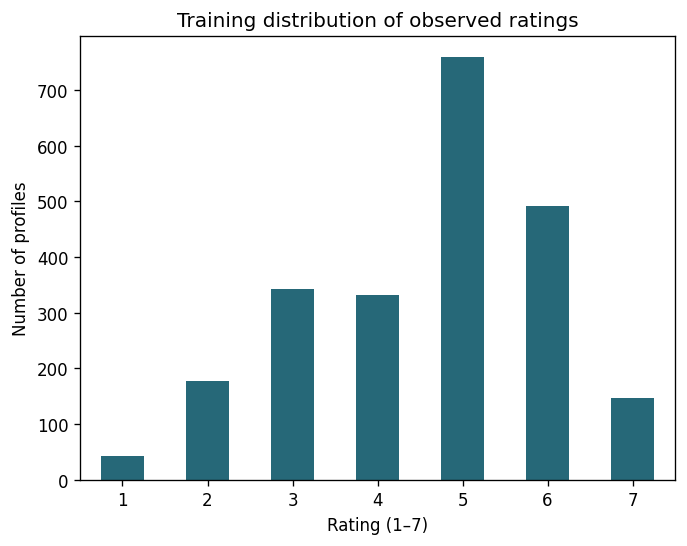

5 is the modal rating (759 training rows). The scale endpoints occur 42 and 146 times and are valid responses.


In [4]:
counts = train.rating.value_counts().reindex(range(1, 8), fill_value=0)
ax = counts.plot.bar(color='#266878', rot=0, title='Training distribution of observed ratings')
ax.set(xlabel='Rating (1–7)', ylabel='Number of profiles')
plt.show()
print(f'{counts.idxmax()} is the modal rating ({counts.max()} training rows). '
      f'The scale endpoints occur {counts.iloc[0]} and {counts.iloc[-1]} times and are valid responses.')

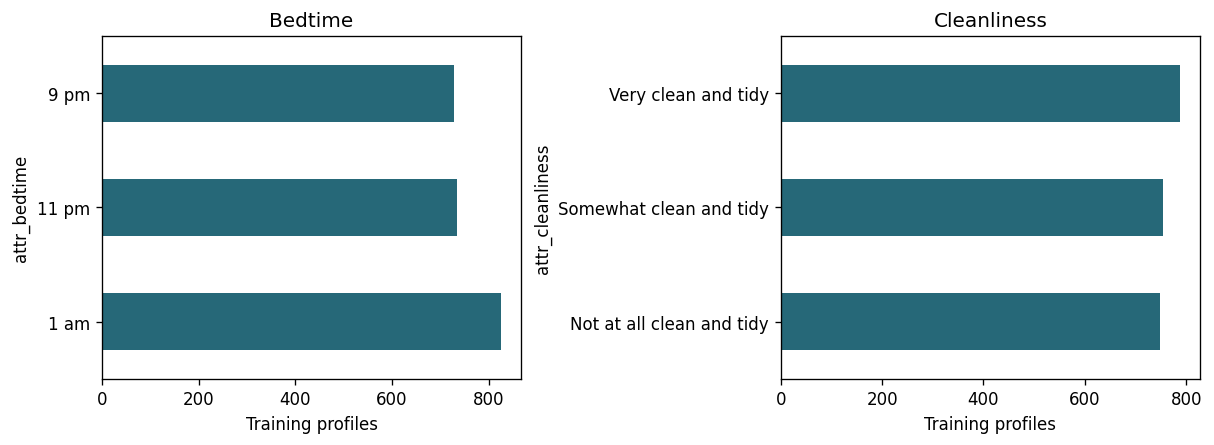

attr_bedtime: largest category has 826 rows and smallest has 729.
attr_cleanliness: largest category has 788 rows and smallest has 748.
These counts reflect the survey design and availability of ratings in the training partition.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout='constrained')
for ax, feature in zip(axes, FEATURES):
    counts = train[feature].fillna('Missing').value_counts().sort_index()
    counts.plot.barh(ax=ax, color='#266878')
    ax.set(title=feature.removeprefix('attr_').capitalize(), xlabel='Training profiles')
    print(f'{feature}: largest category has {counts.max()} rows and smallest has {counts.min()}.')
plt.show()
print('These counts reflect the survey design and availability of ratings in the training partition.')

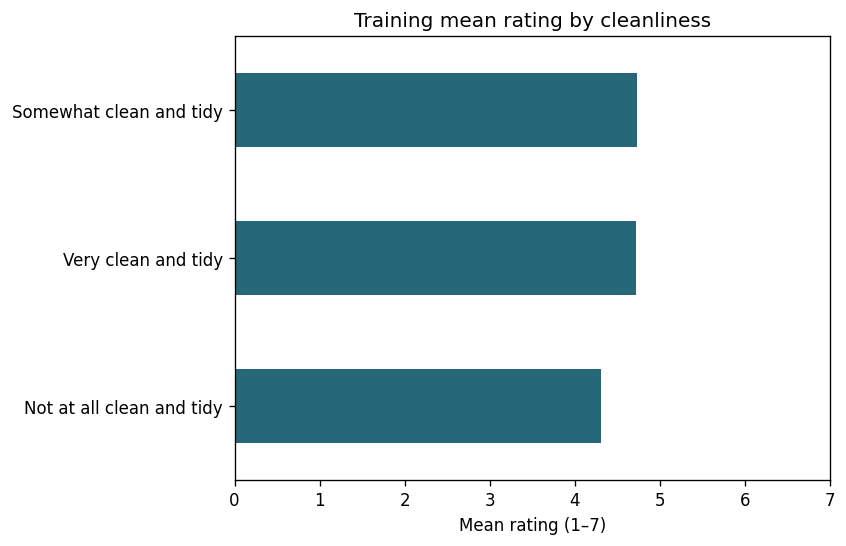

The highest and lowest category means differ by 0.43 points. Repeated judgments within each respondent limit what can be inferred from unadjusted means.


In [6]:
rating_by_level = train.groupby('attr_cleanliness').rating.agg(['mean', 'size']).sort_values('mean')
ax = rating_by_level['mean'].plot.barh(color='#266878', title='Training mean rating by cleanliness')
ax.set(xlim=(0, 7), xlabel='Mean rating (1–7)', ylabel='')
plt.show()
print(f'The highest and lowest category means differ by {rating_by_level["mean"].max() - rating_by_level["mean"].min():.2f} points. '
      'Repeated judgments within each respondent limit what can be inferred from unadjusted means.')

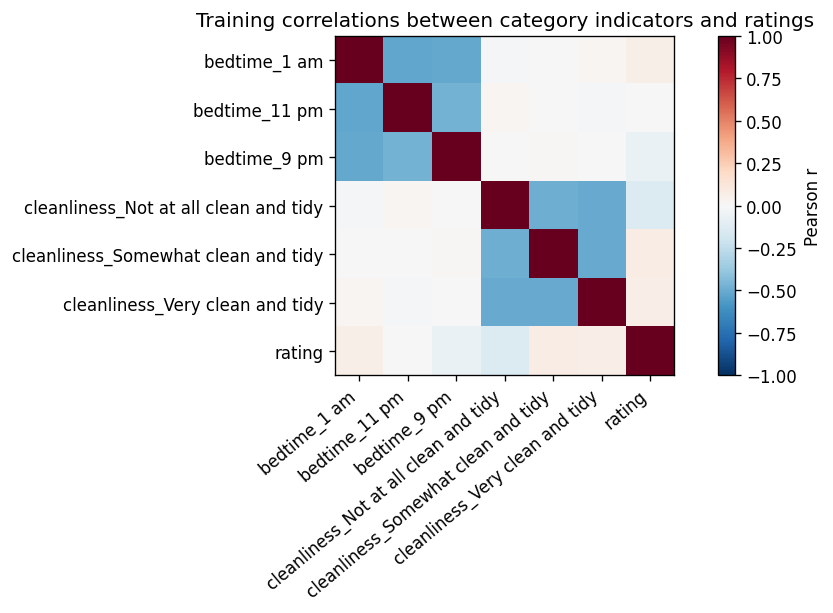

The strongest category–rating association is attr_cleanliness_Not at all clean and tidy (r=-0.14). Negative associations between levels of the same field partly reflect mutually exclusive categories.


In [7]:
# Correlate category membership indicators with each other and the ordered rating.
indicators = pd.get_dummies(train[FEATURES], dummy_na=False, dtype=float)
correlation = indicators.assign(rating=train.rating).corr()
fig, ax = plt.subplots(figsize=(8.5, 5), layout='constrained')
labels = [label.replace('attr_', '') for label in correlation.index]
image = ax.imshow(correlation, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set(xticks=range(len(labels)), yticks=range(len(labels)), yticklabels=labels,
       title='Training correlations between category indicators and ratings')
ax.set_xticklabels(labels, rotation=40, ha='right')
fig.colorbar(image, ax=ax, label='Pearson r')
plt.show()
strongest = correlation.rating.drop('rating').abs().idxmax()
print(f'The strongest category–rating association is {strongest} (r={correlation.loc[strongest, "rating"]:.2f}). '
      'Negative associations between levels of the same field partly reflect mutually exclusive categories.')

## Preprocessing and model comparison
Retain valid ratings at 1 and 7. The two categorical predictors have no continuous outliers and require no scaling. Fill missing predictor values with an explicit category and one-hot encode inside each training pipeline. Unknown levels produce all-zero indicators. Rows with missing labels cannot contribute to rating regression and receive no imputed outcome.

The mean baseline predicts the average training rating. Ridge uses additive category effects with coefficient shrinkage. The shallow forest can capture bedtime–cleanliness interactions, with limited tree depth and minimum leaf support. All settings are fixed before evaluation. Selection uses validation MAE. MAE measures typical error in rating points, RMSE emphasizes large misses, and R² compares squared error with a split-mean reference.

In [8]:
def regression_pipeline(estimator):
    return make_pipeline(SimpleImputer(strategy='constant', fill_value='Missing'),
                         OneHotEncoder(handle_unknown='ignore', sparse_output=False),
                         estimator)

models = {
    'Mean baseline': regression_pipeline(DummyRegressor(strategy='mean')),
    'Ridge': regression_pipeline(Ridge(alpha=10.0)),
    'Shallow forest': regression_pipeline(RandomForestRegressor(
        n_estimators=200, max_depth=4, min_samples_leaf=30, random_state=SEED)),
}

def evaluate(model, part):
    prediction = model.predict(part[FEATURES])
    return {'MAE': mean_absolute_error(part.rating, prediction),
            'RMSE': mean_squared_error(part.rating, prediction) ** 0.5,
            'R²': r2_score(part.rating, prediction)}

fitted = {name: clone(model).fit(train[FEATURES], train.rating)
          for name, model in models.items()}
validation_scores = pd.DataFrame({name: evaluate(model, validation) for name, model in fitted.items()}).T
winner = validation_scores['MAE'].idxmin()
display(validation_scores.round(4))
print('Selected by validation MAE:', winner)

,MAE,RMSE,R²
Mean baseline,1.2818,1.5308,-0.0292
Ridge,1.2496,1.5035,0.0072
Shallow forest,1.2473,1.5040,0.0065


Selected by validation MAE: Shallow forest


### Training-size learning curves
Each point refits preprocessing and the model on a larger nested subset of training respondents. All models see the same subsets and the same fixed validation users. A gap between training and validation MAE can indicate overfitting or differences across respondents.

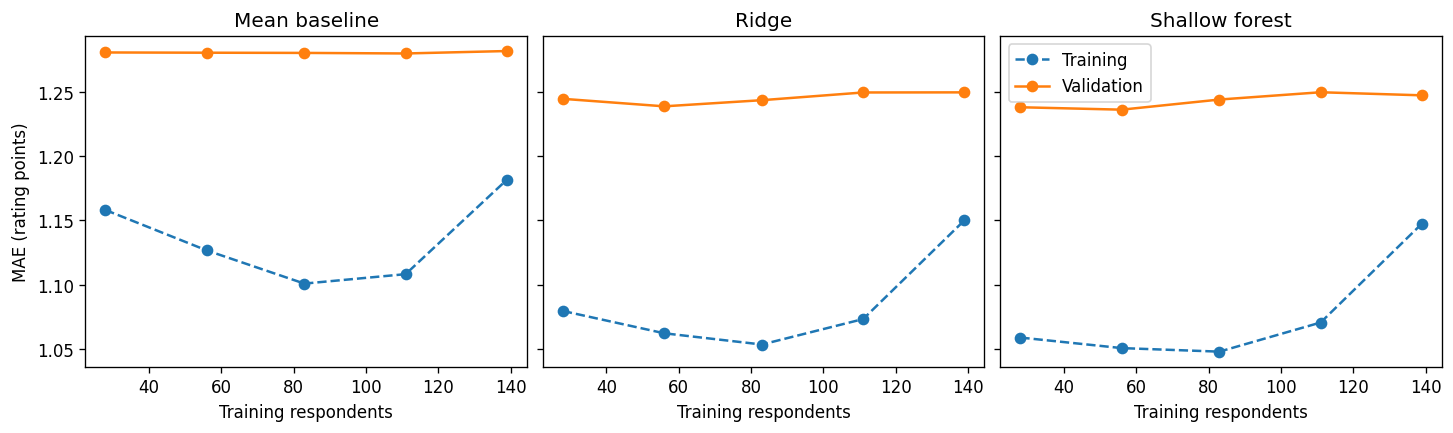

Mean baseline: validation MAE 1.281 → 1.282; final training MAE 1.182.
Ridge: validation MAE 1.245 → 1.250; final training MAE 1.150.
Shallow forest: validation MAE 1.238 → 1.247; final training MAE 1.147.


In [9]:
ordered_groups = np.random.default_rng(SEED).permutation(train.id.unique())
sizes = sorted({round(len(ordered_groups) * fraction) for fraction in [.2, .4, .6, .8, 1.]})
fig, axes = plt.subplots(1, len(models), figsize=(12, 3.5), sharey=True, layout='constrained')
for ax, (name, template) in zip(axes, models.items()):
    train_errors, val_errors = [], []
    for size in sizes:
        subset = train[train.id.isin(ordered_groups[:size])]
        model = clone(template).fit(subset[FEATURES], subset.rating)
        train_errors.append(evaluate(model, subset)['MAE'])
        val_errors.append(evaluate(model, validation)['MAE'])
    ax.plot(sizes, train_errors, 'o--', label='Training')
    ax.plot(sizes, val_errors, 'o-', label='Validation')
    ax.set(title=name, xlabel='Training respondents')
    print(f'{name}: validation MAE {val_errors[0]:.3f} → {val_errors[-1]:.3f}; '
          f'final training MAE {train_errors[-1]:.3f}.')
axes[0].set_ylabel('MAE (rating points)')
axes[-1].legend()
plt.show()

## Final test and exploratory ranking check
Evaluate the fixed models once on held-out respondents. Compare the selected model with the baseline using a paired bootstrap that resamples entire respondents. A secondary observed-choice score uses complete test pairs, assigns half credit for a tied prediction, and uses choice only after training. Complete rated pairs are a selected subset of the original survey tasks. The 1–7 outcome is ordinal, so squared-error metrics assume approximately equal spacing.

In [10]:
test_scores = pd.DataFrame({name: evaluate(model, test) for name, model in fitted.items()}).T
display(test_scores.round(4))
prediction = fitted[winner].predict(test[FEATURES])
baseline = fitted['Mean baseline'].predict(test[FEATURES])
difference = np.abs(test.rating.to_numpy() - prediction) - np.abs(test.rating.to_numpy() - baseline)
cluster = pd.DataFrame({'id': test.id.to_numpy(), 'delta': difference}).groupby('id').delta.agg(['sum', 'size'])
draws = np.random.default_rng(SEED).integers(0, len(cluster), size=(2000, len(cluster)))
bootstrap = cluster['sum'].to_numpy()[draws].sum(axis=1) / cluster['size'].to_numpy()[draws].sum(axis=1)
print(f'Test MAE change vs baseline: {difference.mean():+.4f}; grouped bootstrap 95% interval '
      f'{np.quantile(bootstrap, [.025, .975]).round(4)}')

eligible = test.dropna(subset=['choice'])
pairs = eligible.groupby(['id', 'task']).choice.agg(['size', 'sum'])
complete_keys = pairs.index[(pairs['size'] == 2) & (pairs['sum'] == 1)]
for name, model in fitted.items():
    ranked = eligible[eligible.set_index(['id', 'task']).index.isin(complete_keys)].copy()
    ranked['prediction'] = model.predict(ranked[FEATURES])
    paired = ranked.pivot(index=['id', 'task'], columns='choice', values='prediction')
    margin = paired[1] - paired[0]
    tied = np.isclose(margin, 0)
    accuracy = np.where(tied, 0.5, margin > 0).mean()
    print(f'{name}: forced-choice agreement {accuracy:.3f} across {len(paired)} complete rated pairs')

,MAE,RMSE,R²
Mean baseline,1.1359,1.3454,-0.0001
Ridge,1.1059,1.3222,0.0341
Shallow forest,1.1017,1.3209,0.0360


Test MAE change vs baseline: -0.0341; grouped bootstrap 95% interval [-0.0591 -0.0121]
Mean baseline: forced-choice agreement 0.500 across 230 complete rated pairs
Ridge: forced-choice agreement 0.698 across 230 complete rated pairs
Shallow forest: forced-choice agreement 0.672 across 230 complete rated pairs


## InterNest implications
The experiment estimates how hypothetical profiles are rated in this survey. The predictors omit the searcher's desired behavior, bilateral constraints, and observed cohabitation. See the [academic report](../reports/lab-06.md) for the numerical interpretation, literature review, and how to evaluate a future local feedback model.